## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nathan Brence

**Date:** 10/14/2026

In [108]:
#Part 1
#Question 1

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

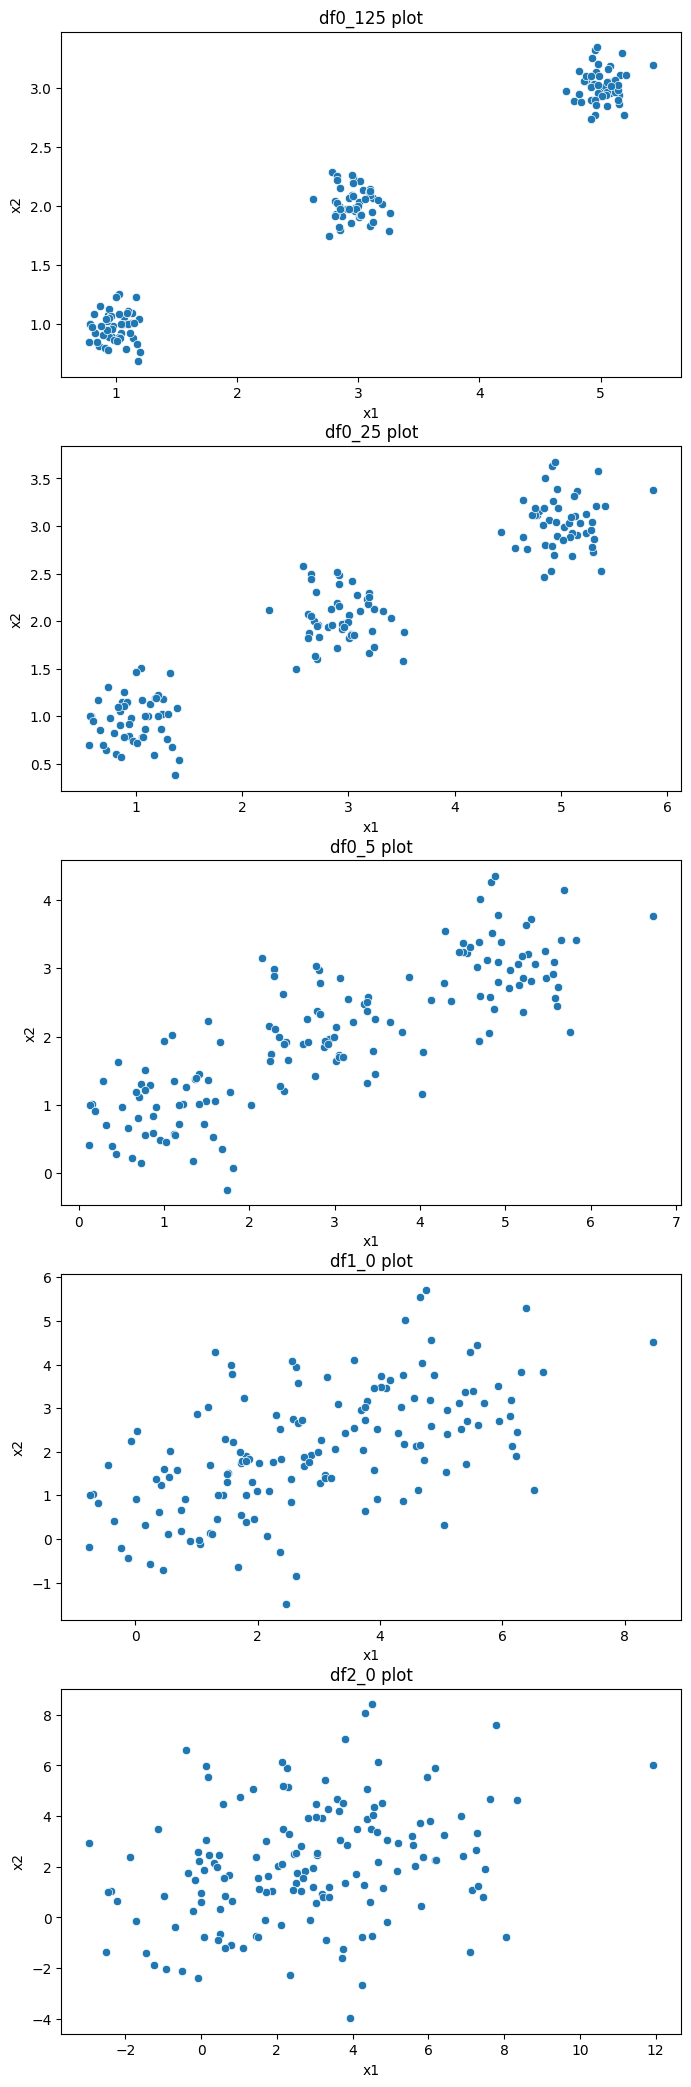

In [109]:
#Part 1
#Question 2
fig, ax = plt.subplots(nrows=5, figsize=(8, 26))

df_list = [(0, "df0_125", df0_125), 
           (1, "df0_25", df0_25), 
           (2, "df0_5", df0_5), 
           (3, "df1_0", df1_0), 
           (4, "df2_0", df2_0)]

for i, name, df in df_list:
    sns.scatterplot(data=df, x="x1", y="x2", ax=ax[i])
    ax[i].set_title(f"{name} plot")



As noise increases, the visual distinctness of each cluster decreases. This can be observed from how points in dataframes with greater noise are more distant from the center of each cluster than those with less noise.  

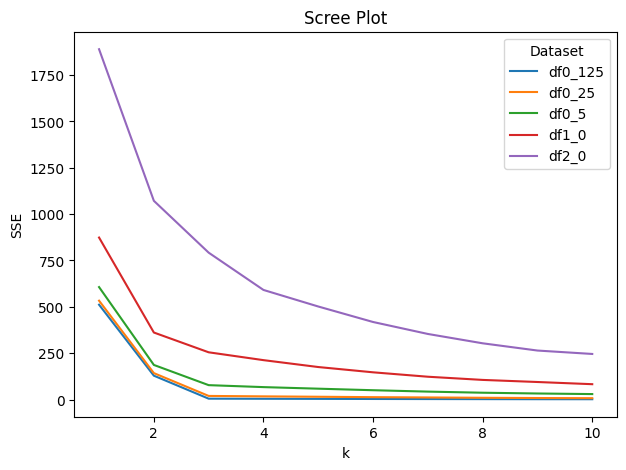

In [110]:
#Part 1
#Question 3

from sklearn.cluster import KMeans

fig, ax = plt.subplots(figsize=(7, 5))

df_list = [("df0_125", df0_125), 
           ("df0_25", df0_25), 
           ("df0_5", df0_5), 
           ("df1_0", df1_0), 
           ("df2_0", df2_0)]

ks = np.arange(1, 11)
features = ["x1", "x2"]

for name, df in df_list:
    X = df.loc[:, features]
    SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    sns.lineplot(x=ks, y=SSE, label=name, ax=ax)

ax.set(title="Scree Plot", xlabel="k", ylabel="SSE")
ax.legend(title="Dataset")
plt.show()

As noise increases, the overall SSE increases for each value of k. In addition, increased noise makes the presence of an elbow point in a scree plot less distinct, since the noisiest datasets continuously decrease in SSE as k goes up rather than reaching a point where the fall in SSE is negligible enough to call it an elbow. 

Part 1, Question 4: The intuition behind choosing the elbow point as the number of clusters (k) in a KMeans model is that it's the point where further decreases in SSE would be unpreferable since it would result in overfitting and not tell us anything significant about the data. To use the simulation as an example, although having k = 10 on the df0_125 dataset would result in the lowest SSE, but since there are three clear clusters in the data, implementing a ten cluster model would force otherwise similar points into different clusters. As a result, any signal that would've otherwise come from the data would be distorted since the model isn't representative of the patterns within it. 

In [111]:
#Part 2
#Question 1

sipri = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
sipri = sipri[sipri["Year"] == 2020]
sipri = sipri.dropna(how='any',axis=0)

# Additional cleaning required: turn proportions into percentages
sipri["Percent of GDP"] = sipri["Percent of GDP"] * 100
sipri["Percent of Government Spending"] = sipri["Percent of Government Spending"] * 100

[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

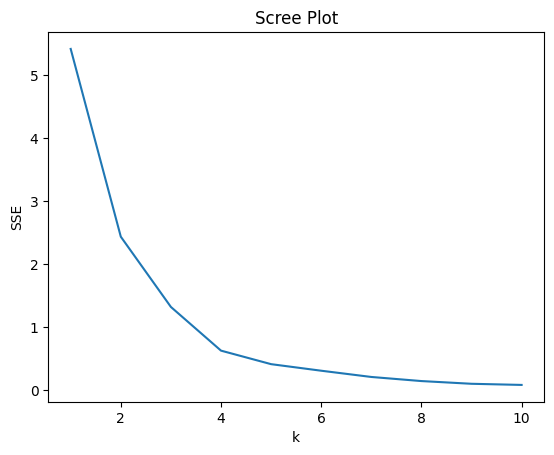

In [112]:
#Part 2
#Question 2

features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = sipri.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

fig, ax = plt.subplots()
ks = np.arange(1, 11)

SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE, ax=ax)
ax.set(title="Scree Plot", xlabel="k", ylabel="SSE") # algorithm reveals that k = 5 is the elbow point

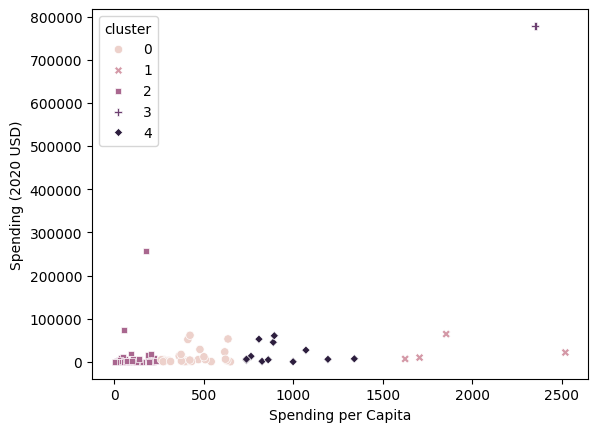

In [113]:
model = KMeans(n_clusters=5, n_init="auto", random_state=0).fit(X)
sipri["cluster"] = model.labels_
ax = sns.scatterplot(data=sipri, x="Spending per Capita", y="Spending (2020 USD)", hue="cluster", style="cluster")

In [114]:
sipri.groupby("cluster")[["Spending (2020 USD)", "Spending per Capita"]].describe()

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      27.0   11690.329234  17414.968840     405.790494   
1                       4.0   25823.645885  26608.626022    6941.042345   
2                     104.0    4994.487667  26245.548160       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   
4                      12.0   19166.438746  21781.990464     436.548223   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          1547.724900    4302.975037   12820.984515   61712.537169   
1          9219.189158   15897.570598   32502.027326   64558.400000   
2           106.486133     356.231203    1675.110704  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   
4          4757.206431    6829.774946   31856.667202   60675.039625   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      27.0   431.058499  122.592253   262.621971   
1                       4.0  1926.418480  407.210137  1625.156250   
2                     104.0    66.233766   66.077594     0.580129   
3                       1.0  2351.631858         NaN  2351.631858   
4                      12.0   926.579014  190.229150   737.690186   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         338.334194   410.914568   504.630211   648.227625  
1        1685.593092  1780.059564  2020.884951  2520.398541  
2          14.009571    43.213838    99.478016   246.772892  
3        2351.631858  2351.631858  2351.631858  2351.631858  
4         796.986068   873.912116  1016.880470  1341.058851

Based on the scatterplot and cluster membership table, it's clear that the dominant factor in cluster membership is Spending per Capita rather than total spending. This becomes evident when observing the scatterplot, which shows that change in cluster progresses across the x-axis and that certain points in cluster two with high total spending are still grouped as such, demonstrating total spending has little effect on clustering. Such a fact is reinforced by the cluster membership table, showing that each cluster has a dramatically different spending per capita whilst total spending doesn't vary much. The only exception to this rule is the United States, which has by far the highest total spending as well as massive spending per capita, being grouped in a cluster of its own.

[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

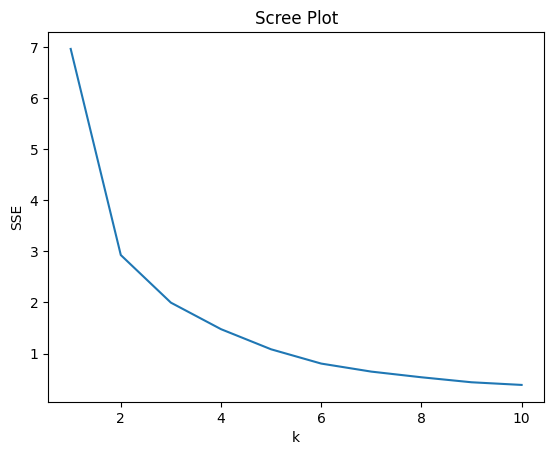

In [115]:
# Part 2
# Question 3

features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = sipri.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

fig, ax = plt.subplots()
ks = np.arange(1, 11)

SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE, ax=ax)
ax.set(title="Scree Plot", xlabel="k", ylabel="SSE") # algorithm reveals that k = 6 is the elbow point

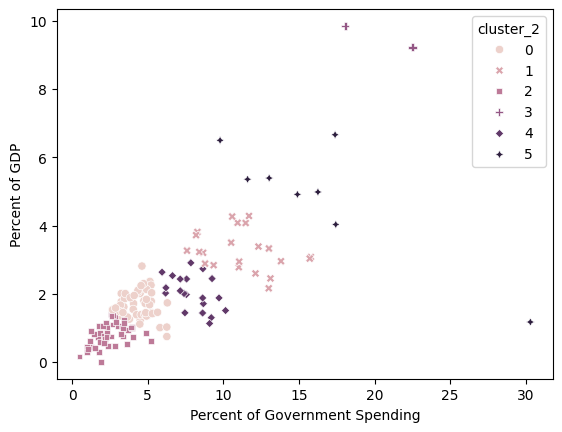

In [116]:
model = KMeans(n_clusters=6, n_init="auto", random_state=0).fit(X)
sipri["cluster_2"] = model.labels_
ax = sns.scatterplot(data=sipri, x="Percent of Government Spending", y="Percent of GDP", hue="cluster_2", style="cluster_2")

In [117]:
sipri.groupby("cluster_2")[["Percent of GDP", "Percent of Government Spending"]].describe()

Percent of GDP                                                    \
                   count      mean       std       min       25%       50%   
cluster_2                                                                    
0                   48.0  1.670406  0.399132  0.749454  1.397219  1.644332   
1                   22.0  3.266226  0.581845  2.161792  2.899196  3.214770   
2                   48.0  0.824076  0.341713  0.005400  0.579294  0.839281   
3                    2.0  9.534054  0.442619  9.221075  9.377565  9.534054   
4                   20.0  2.034603  0.505506  1.131726  1.660328  2.015374   
5                    8.0  4.875316  1.720907  1.174170  4.691980  5.169000   

                              Percent of Government Spending             \
                75%       max                          count       mean   
cluster_2                                                                 
0          1.964379  2.813162                           48.0   4.425248   
1          3.663279  4.281029                           22.0  11.161087   
2          1.060771  1.415945                           48.0   2.540146   
3          9.690544  9.847033                            2.0  20.285184   
4          2.437045  2.907744                           20.0   7.958818   
5          5.666888  6.659994                            8.0  16.339789   

                                                                            
                std        min        25%        50%        75%        max  
cluster_2                                                                   
0          0.941162   2.664190   3.629364   4.534952   5.011681   6.299605  
1          2.347580   7.600472   8.935842  11.037974  12.834272  15.791773  
2          1.039912   0.489643   1.829403   2.494383   3.326097   5.222445  
3          3.139303  18.065361  19.175273  20.285184  21.395095  22.505006  
4          1.224164   5.951952   7.154975   7.714474   8.785625  10.150132  
5          6.274812   9.788241  12.676710  15.579836  17.403381  30.302658

Compared to part 2, my results show that clustering is determined by a combination of both features rather than just one. This can be seen in the scatterplot, where analyzing the position of a point in one cluster and a point in a different cluster shows that a change in either Percent of Government Spending or Percent of GDP results in a point being clustered differently. Such a fact is further confirmed through the cluster membership tables, which indicate that all of the clusters have different scales of each feature.

[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

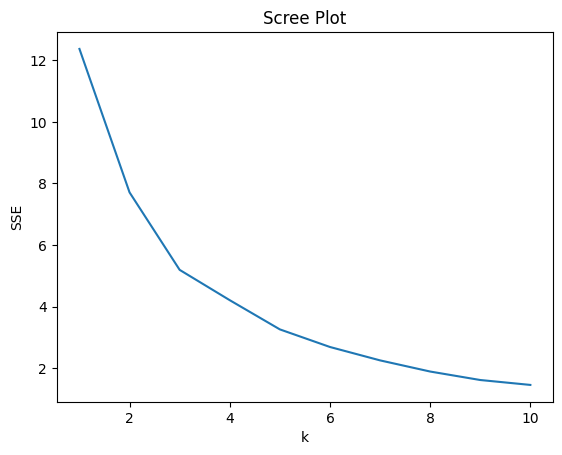

In [118]:
#Part 2
#Question 4

features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = sipri.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

fig, ax = plt.subplots()
ks = np.arange(1, 11)

SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE, ax=ax)
ax.set(title="Scree Plot", xlabel="k", ylabel="SSE") # algorithm reveals that k = 8 is the elbow point

In [119]:
model = KMeans(n_clusters=8, n_init="auto", random_state=0).fit(X)
sipri["cluster_3"] = model.labels_

#can't create scatterplot like those above due to four variables: create cluster membership table instead
display(sipri.groupby("cluster_3")[["Percent of GDP", "Percent of Government Spending"]].describe())
display(sipri.groupby("cluster_3")[["Spending (2020 USD)", "Spending per Capita"]].describe())

Percent of GDP                                                    \
                   count      mean       std       min       25%       50%   
cluster_3                                                                    
0                   26.0  1.658500  0.552503  0.627338  1.368857  1.532432   
1                    3.0  4.931405  1.814116  2.942885  4.149074  5.355263   
2                   65.0  1.033278  0.450452  0.005400  0.738680  1.026224   
3                   16.0  3.620025  1.372715  1.174170  2.865229  3.356238   
4                    1.0  3.717885       NaN  3.717885  3.717885  3.717885   
5                    2.0  9.534054  0.442619  9.221075  9.377565  9.534054   
6                   31.0  2.237847  0.648472  1.131726  1.790911  2.089015   
7                    4.0  3.799209  0.686350  2.778110  3.750326  4.077638   

                              Percent of Government Spending             \
                75%       max                          count       mean   
cluster_3                                                                 
0          2.043057  2.813162                           26.0   3.327996   
1          5.925665  6.496067                            3.0  10.814120   
2          1.387607  1.856629                           65.0   3.413842   
3          4.438786  6.659994                           16.0  15.028691   
4          3.717885  3.717885                            1.0   8.197624   
5          9.690544  9.847033                            2.0  20.285184   
6          2.683973  3.811849                           31.0   7.619764   
7          4.126521  4.263450                            4.0  11.009537   

                                                                            
                std        min        25%        50%        75%        max  
cluster_3                                                                   
0          1.177121   1.161349   2.602778   3.207741   4.464478   5.220948  
1          0.930954   9.788241  10.418586  11.048932  11.327059  11.605186  
2          1.400954   0.489643   2.280812   3.407953   4.506988   6.268550  
3          4.558160  10.518594  12.834272  13.466335  15.908122  30.302658  
4               NaN   8.197624   8.197624   8.197624   8.197624   8.197624  
5          3.139303  18.065361  19.175273  20.285184  21.395095  22.505006  
6          1.518631   4.359187   6.470780   7.600472   8.674879  10.150132  
7          0.366327  10.586068  10.857101  10.987231  11.139667  11.477618

Spending (2020 USD)                                              \
                        count           mean           std            min   
cluster_3                                                                   
0                        26.0   15330.618681  18923.469359     405.790494   
1                         3.0   12912.061180   7859.666063    6941.042345   
2                        65.0    1355.055919   3001.122751       8.622460   
3                        16.0    3967.259220   4769.356236     198.530037   
4                         1.0  778397.200000           NaN  778397.200000   
5                         2.0   35327.054356  41339.365456    6095.708713   
6                        31.0   12894.788309  47370.663023      23.306688   
7                         4.0   27269.464334  31137.007397     436.548223   

                                                                       \
                     25%            50%            75%            max   
cluster_3                                                               
0            3176.345598    5857.060906   21818.934764   60675.039625   
1            8459.806887    9978.571429   15897.570598   21816.569767   
2              78.965006     239.887164    1074.134515   19591.209004   
3             623.936771    1988.654264    6011.750171   15825.143121   
4          778397.200000  778397.200000  778397.200000  778397.200000   
5           20711.381534   35327.054356   49942.727178   64558.400000   
6             250.870593     934.311154    4805.246469  257973.429834   
7            1162.727481   23464.385971   49571.122823   61712.537169   

          Spending per Capita                                        \
                        count         mean         std          min   
cluster_3                                                             
0                        26.0   612.677541  241.189507   362.467076   
1                         3.0  1950.431166  495.247907  1625.156250   
2                        65.0    61.743745   73.965325     0.580129   
3                        16.0   123.828742   90.293998    19.655822   
4                         1.0  2351.631858         NaN  2351.631858   
5                         2.0  1523.989576  467.243215  1193.598730   
6                        31.0   109.447005  114.339588     5.674383   
7                         4.0   783.791012  251.087125   422.879776   

                                                               
                   25%          50%          75%          max  
cluster_3                                                      
0           413.682029   579.004604   738.120108  1341.058851  
1          1665.447478  1705.738706  2113.068623  2520.398541  
2            11.417058    34.318585    80.480192   303.716973  
3            45.109825   102.874092   204.615548   281.522789  
4          2351.631858  2351.631858  2351.631858  2351.631858  
5          1358.794153  1523.989576  1689.184999  1854.380422  
6            19.048721    72.164472   142.682321   500.637259  
7           724.750746   856.659043   915.699309   998.966186

Compared to the previous two parts, the results from using all four numeric variables show less discernable patterns. In other words, rather than clustering being reliant on a single variable or a relationship between the two, the resulting clusters have far less intuitive placements, likely stemming from the fact that they're influenced by a wider variety of variables. The only shared traits between this model and the previous two are that the United States of America is in a cluster of its own and that Percent of GDP and Percent of Government Spending rise with each other.

Part 2, Question 5: Each of the KMeans algorithms demonstrated that there are a series of patterns and interesting observations within the data. First of all, the United States has been shown to be an outlier in each of the models (often having a cluster only to itself), indicating that the country is unique in its military spending. Secondly, Percent of GDP and Percent of Government Spending have a direct relationship, which is intuitive since GDP and a government's budget are closely correlated. Lastly, Spending per Capita, since it was one of the main determinants of how data was clustered, is likely the most influential variable in classifying government spending behavior.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [120]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]